In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import requests
from PIL import Image
from io import BytesIO
from urllib.parse import unquote_plus
import matplotlib.pyplot as plt
import os

In [2]:
MEMBERSHIP_PATH   = "brain/poi_fuzzy_memberships.npy"
CLUSTER_IDS_PATH  = "brain/poi_cluster_ids.npy"
FILTERED_POI_PATH = "brain/filtered_poi_ids.npy"
FILTERED_PID_PATH = "brain/filtered_photo_ids.npy"
CSV_PATH          = "brain/usa_europe_geotagged.csv"
OUTPUT_DIR        = "brain/"

print("Config ready.")

Config ready.


In [3]:
print("Loading data...")
poi_memberships  = np.load(MEMBERSHIP_PATH)
unique_pois      = np.load(CLUSTER_IDS_PATH)
filtered_poi_ids = np.load(FILTERED_POI_PATH)
filtered_pids    = np.load(FILTERED_PID_PATH)

n_clusters  = poi_memberships.shape[1]
hard_labels = poi_memberships.argmax(axis=1)

print("Loading CSV...")
df            = pd.read_csv(CSV_PATH)
df['photoid'] = df['photoid'].astype(int)
df_indexed    = df.set_index('photoid')

print(f"Memberships  : {poi_memberships.shape}")
print(f"Unique POIs  : {len(unique_pois):,}")
print(f"N clusters   : {n_clusters}")
print(f"CSV rows     : {len(df):,}")
print(f"\nPOIs per cluster:")
for k in range(n_clusters):
    print(f"  Cluster {k}: {(hard_labels == k).sum():,} POIs")

Loading data...
Loading CSV...
Memberships  : (169845, 6)
Unique POIs  : 169,845
N clusters   : 6
CSV rows     : 7,672,417

POIs per cluster:
  Cluster 0: 21,983 POIs
  Cluster 1: 29,928 POIs
  Cluster 2: 22,883 POIs
  Cluster 3: 28,920 POIs
  Cluster 4: 33,361 POIs
  Cluster 5: 32,770 POIs


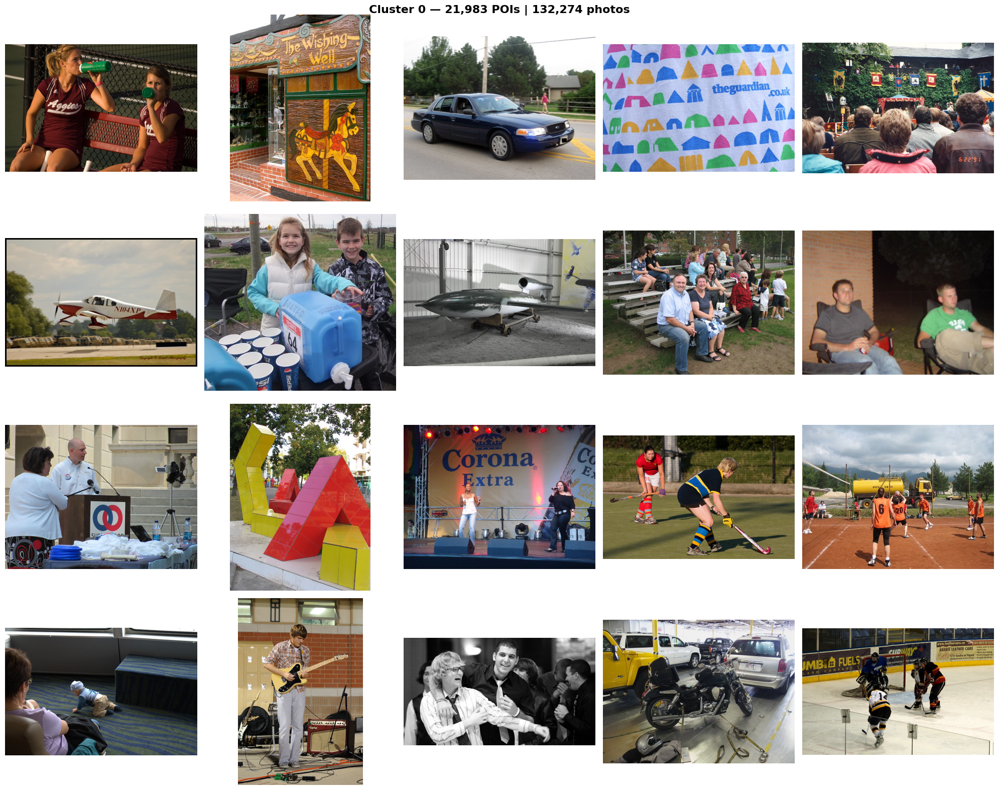

Cluster 0: 20 images shown.



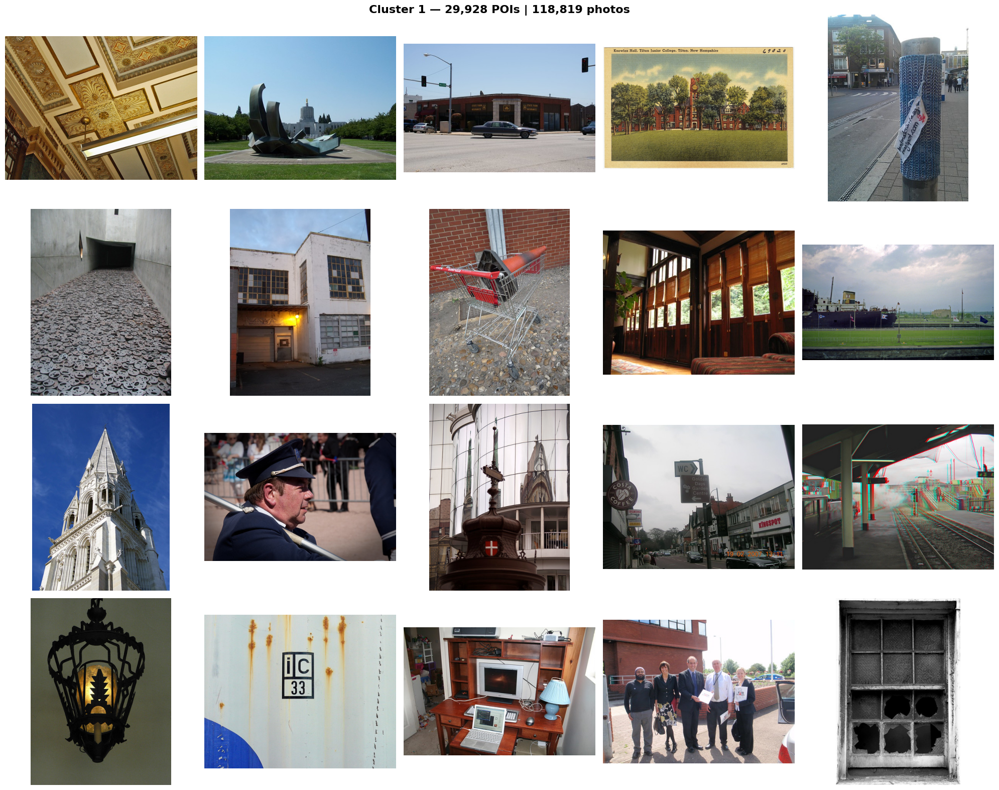

Cluster 1: 20 images shown.



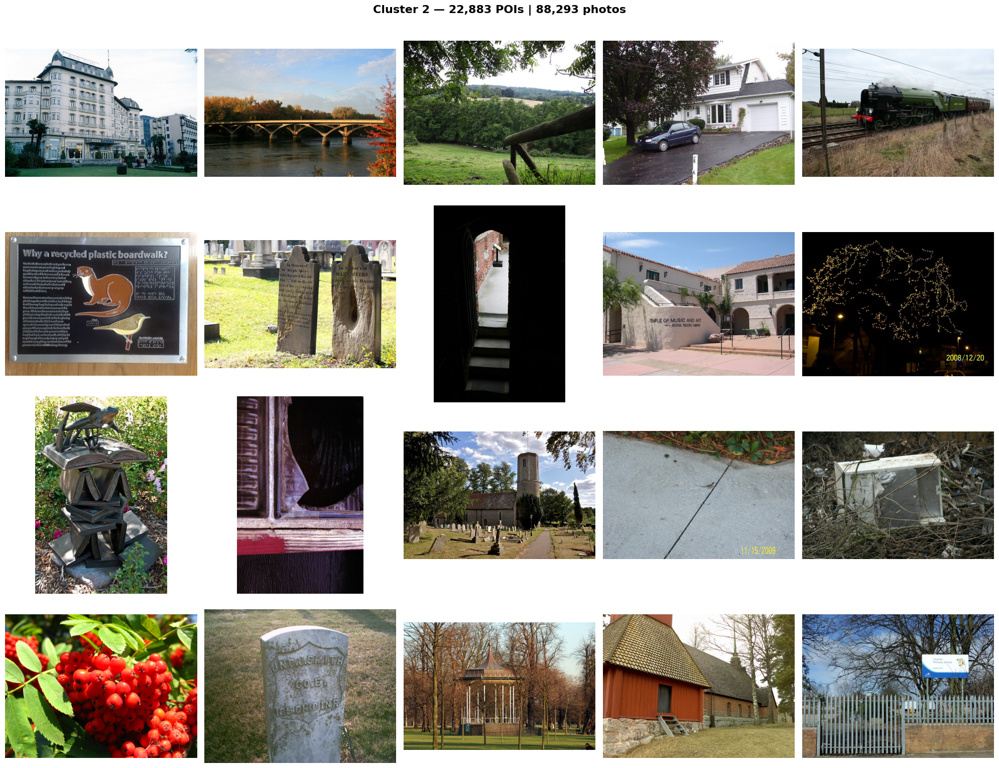

Cluster 2: 20 images shown.



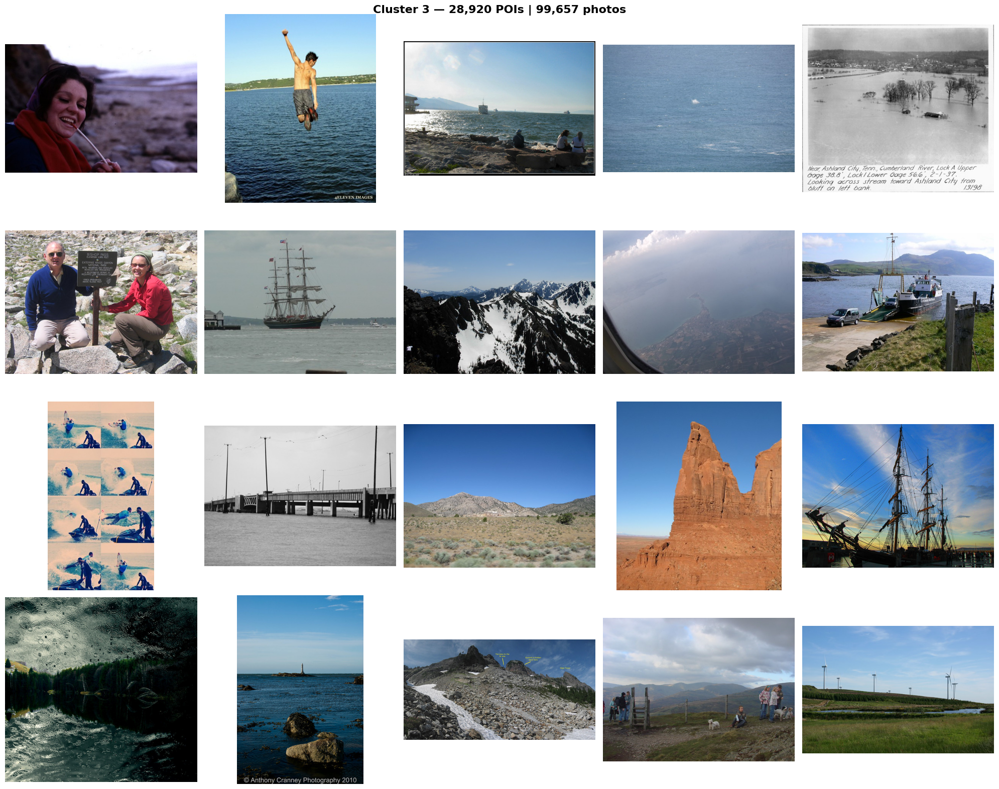

Cluster 3: 20 images shown.



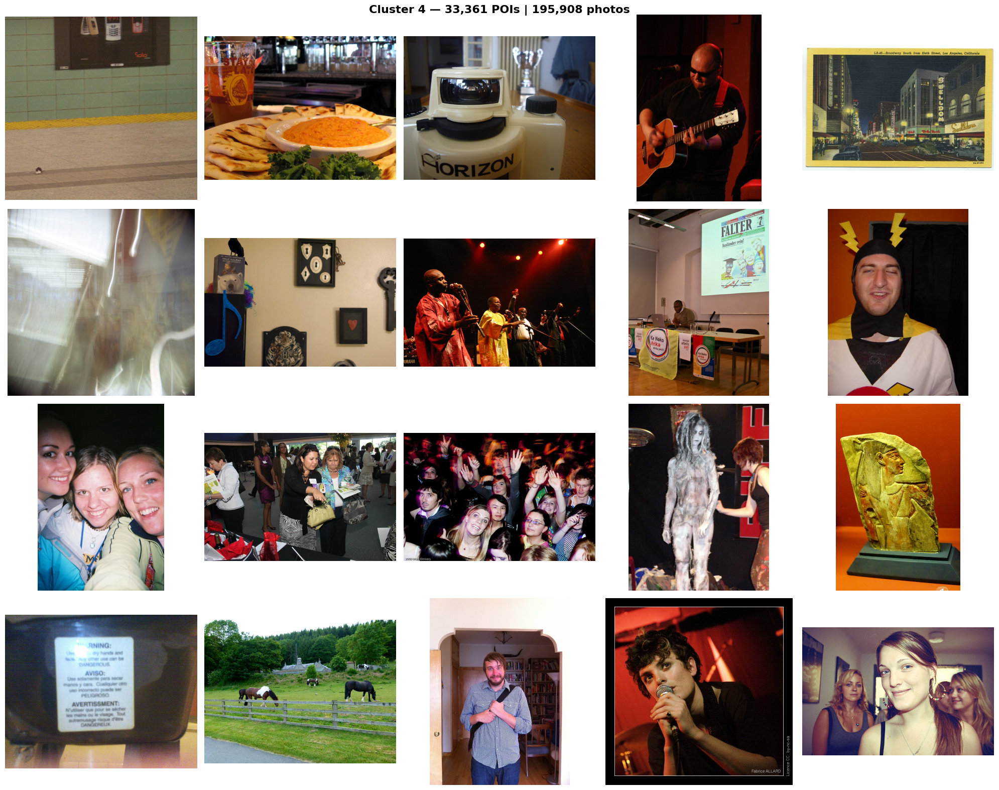

Cluster 4: 20 images shown.



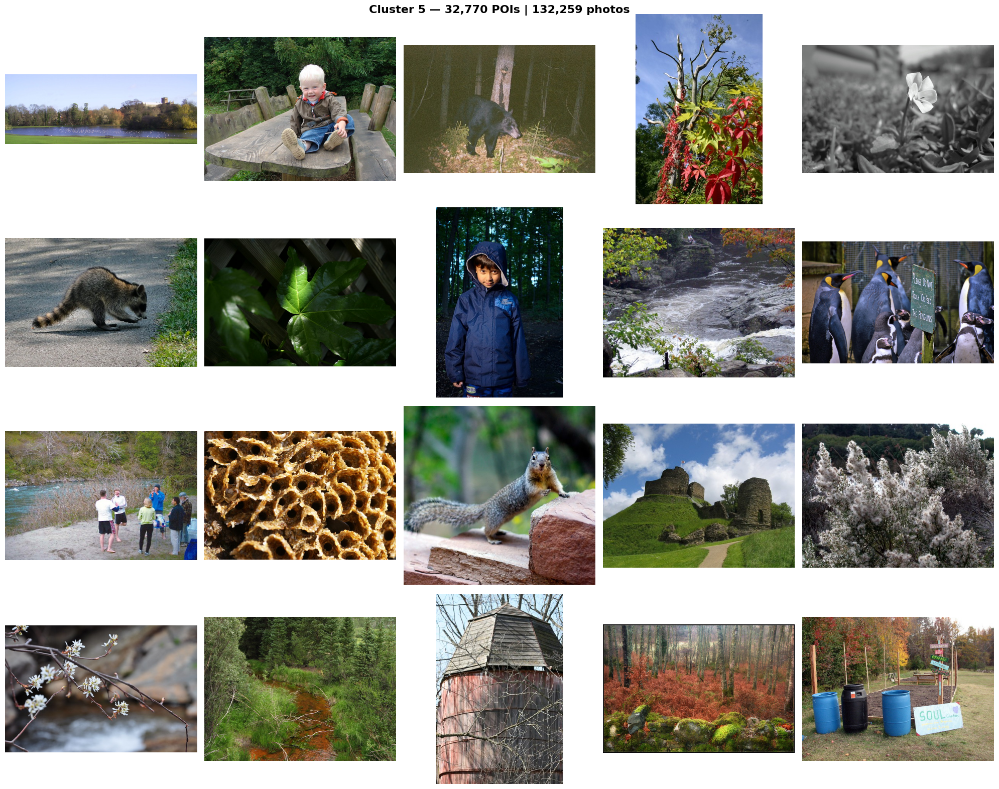

Cluster 5: 20 images shown.



In [4]:
def fetch_image(url, timeout=5):
    try:
        r = requests.get(url, timeout=timeout)
        return Image.open(BytesIO(r.content)).convert('RGB')
    except:
        return None

for k in range(n_clusters):
    # Get all photo IDs in this cluster
    cluster_poi_ids    = unique_pois[hard_labels == k]
    cluster_photo_mask = np.isin(filtered_poi_ids, cluster_poi_ids)
    cluster_pids       = filtered_pids[cluster_photo_mask]

    # Random sample of 20
    sample_pids = np.random.choice(
        cluster_pids,
        size=min(20, len(cluster_pids)),
        replace=False
    )

    # Fetch images
    images = []
    for pid in sample_pids:
        if int(pid) not in df_indexed.index:
            continue
        url = unquote_plus(str(df_indexed.loc[int(pid)]['downloadurl']))
        img = fetch_image(url)
        if img is not None:
            images.append(img)

    # Plot 4x5 grid
    fig, axes = plt.subplots(4, 5, figsize=(20, 16))
    fig.suptitle(
        f"Cluster {k} — {(hard_labels == k).sum():,} POIs | {len(cluster_pids):,} photos",
        fontsize=16, fontweight='bold'
    )
    for idx, ax in enumerate(axes.flat):
        if idx < len(images):
            ax.imshow(images[idx])
        else:
            ax.set_facecolor('#f0f0f0')
        ax.axis('off')

    plt.tight_layout()
    plt.show()
    print(f"Cluster {k}: {len(images)} images shown.\n")

In [5]:
cluster_labels = {
    0: {
        "label"      : "Live Events & Recreation",
        "description": "Sports venues, concerts, fairs, outdoor games and public performances.",
        "keywords"   : ["sports", "concert", "festival", "fair", "recreation"]
    },
    1: {
        "label"      : "Urban & Street Architecture",
        "description": "City streets, urban buildings, transit infrastructure and architectural details.",
        "keywords"   : ["urban", "street", "architecture", "building", "transit"]
    },
    2: {
        "label"      : "Historic & Rural Heritage",
        "description": "Historic buildings, cemeteries, countryside, old churches and rural landscapes.",
        "keywords"   : ["historic", "heritage", "rural", "cemetery", "countryside"]
    },
    3: {
        "label"      : "Scenic Nature & Waterscapes",
        "description": "Oceans, mountains, coastlines, ships and sweeping natural landscapes.",
        "keywords"   : ["ocean", "mountain", "coast", "landscape", "waterscape"]
    },
    4: {
        "label"      : "Nightlife & Social Scenes",
        "description": "Bars, restaurants, concerts, indoor gatherings and social events.",
        "keywords"   : ["nightlife", "bar", "food", "concert", "social"]
    },
    5: {
        "label"      : "Green Nature & Wildlife",
        "description": "Forests, wildlife, rivers, parks and close-up flora and fauna.",
        "keywords"   : ["forest", "wildlife", "nature", "park", "flora"]
    },
}
print("Labels defined.")

Labels defined.


In [6]:
rows = []
for i, poi in enumerate(unique_pois):
    mem      = poi_memberships[i]
    top2_idx = np.argsort(mem)[-2:][::-1]

    primary_cluster   = int(top2_idx[0])
    secondary_cluster = int(top2_idx[1])

    rows.append({
        "poi_id"            : int(poi),
        "primary_cluster"   : primary_cluster,
        "primary_label"     : cluster_labels[primary_cluster]['label'],
        "primary_prob"      : round(float(mem[primary_cluster]), 4),
        "secondary_cluster" : secondary_cluster,
        "secondary_label"   : cluster_labels[secondary_cluster]['label'],
        "secondary_prob"    : round(float(mem[secondary_cluster]), 4),
        **{f"cluster_{k}_prob": round(float(mem[k]), 4) for k in range(n_clusters)}
    })

poi_label_df = pd.DataFrame(rows)
print(poi_label_df.head(5).to_string())
print(f"\nShape: {poi_label_df.shape}")

   poi_id  primary_cluster              primary_label  primary_prob  secondary_cluster           secondary_label  secondary_prob  cluster_0_prob  cluster_1_prob  cluster_2_prob  cluster_3_prob  cluster_4_prob  cluster_5_prob
0       0                4  Nightlife & Social Scenes        0.9148                  0  Live Events & Recreation          0.0487          0.0487          0.0277          0.0050          0.0018          0.9148          0.0021
1       1                4  Nightlife & Social Scenes        0.6189                  0  Live Events & Recreation          0.2526          0.2526          0.1085          0.0126          0.0042          0.6189          0.0033
2       2                4  Nightlife & Social Scenes        0.8254                  0  Live Events & Recreation          0.1339          0.1339          0.0325          0.0047          0.0018          0.8254          0.0017
3       3                4  Nightlife & Social Scenes        0.8268                  0  Live Events 

In [7]:
import json

poi_label_df.to_csv(
    os.path.join(OUTPUT_DIR, "poi_aesthetic_labels.csv"), index=False
)
with open(os.path.join(OUTPUT_DIR, "cluster_label_map.json"), 'w') as f:
    json.dump(cluster_labels, f, indent=2)

print("Saved:")
print(f"  poi_aesthetic_labels.csv : {poi_label_df.shape}")
print(f"  cluster_label_map.json")
print("\nCluster Summary:")
for k, v in cluster_labels.items():
    count = (hard_labels == k).sum()
    print(f"  Cluster {k} | {v['label']:35s} | {count:,} POIs")
print("\nNB9 Complete. Ready for NB10.")

Saved:
  poi_aesthetic_labels.csv : (169845, 13)
  cluster_label_map.json

Cluster Summary:
  Cluster 0 | Live Events & Recreation            | 21,983 POIs
  Cluster 1 | Urban & Street Architecture         | 29,928 POIs
  Cluster 2 | Historic & Rural Heritage           | 22,883 POIs
  Cluster 3 | Scenic Nature & Waterscapes         | 28,920 POIs
  Cluster 4 | Nightlife & Social Scenes           | 33,361 POIs
  Cluster 5 | Green Nature & Wildlife             | 32,770 POIs

NB9 Complete. Ready for NB10.
